Question 1


===== MIN-MAX NORMALIZED (preview) =====
   Hydro (MW)  Solar (MW)  Demand (MW)
0      0.2042      0.0000       0.6539
1      0.1905      0.0000       0.6271
2      0.1911      0.0000       0.6159
3      0.1903      0.0000       0.5967
4      0.1895      0.0000       0.5715

===== Z-SCORE NORMALIZED (preview) =====
   Hydro (MW)  Solar (MW)  Demand (MW)
0      0.1753     -0.8342       0.6220
1      0.0109     -0.8342       0.5198
2      0.0177     -0.8342       0.4771
3      0.0086     -0.8342       0.4039
4     -0.0007     -0.8342       0.3078

===== IQR NORMALIZED (preview) =====
   Hydro (MW)  Solar (MW)  Demand (MW)
0      0.8342      0.0000       0.8837
1      0.6304      0.0000       0.8249
2      0.6388      0.0000       0.8003
3      0.6274      0.0000       0.7583
4      0.6159      0.0000       0.7029


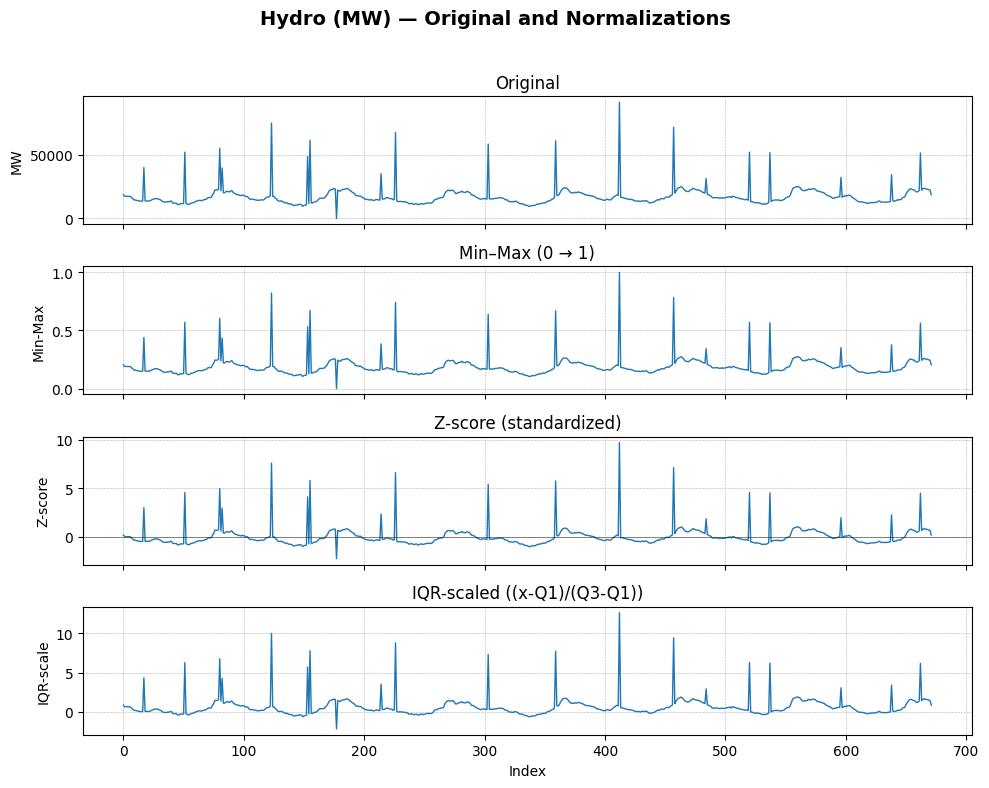

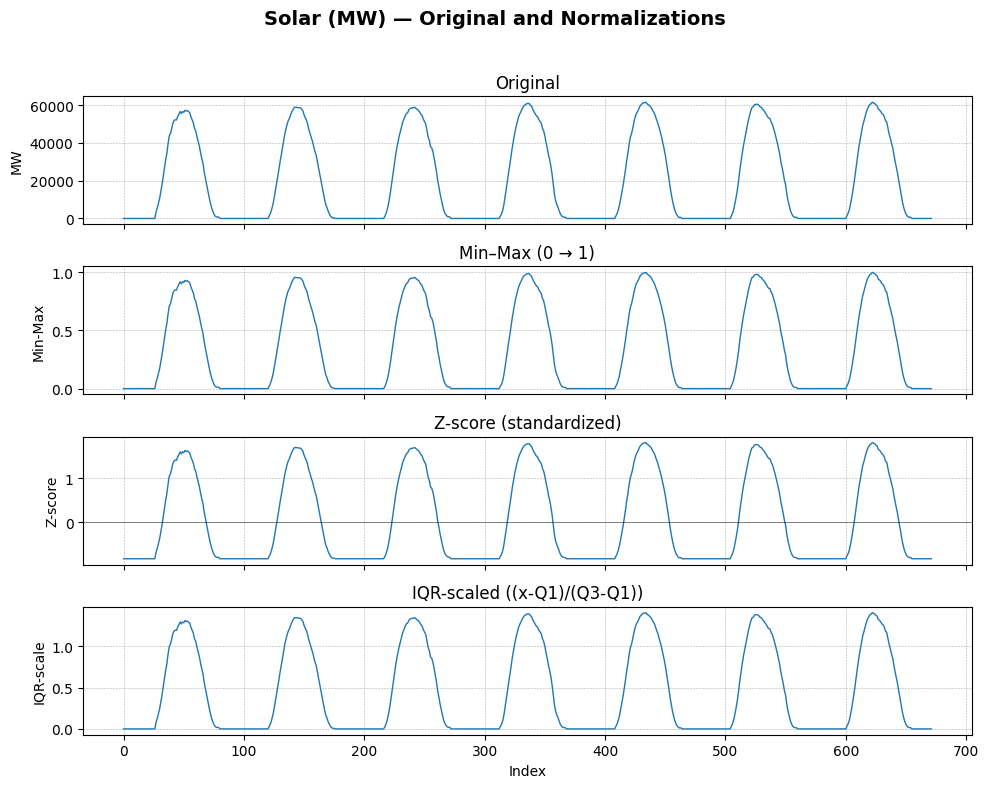

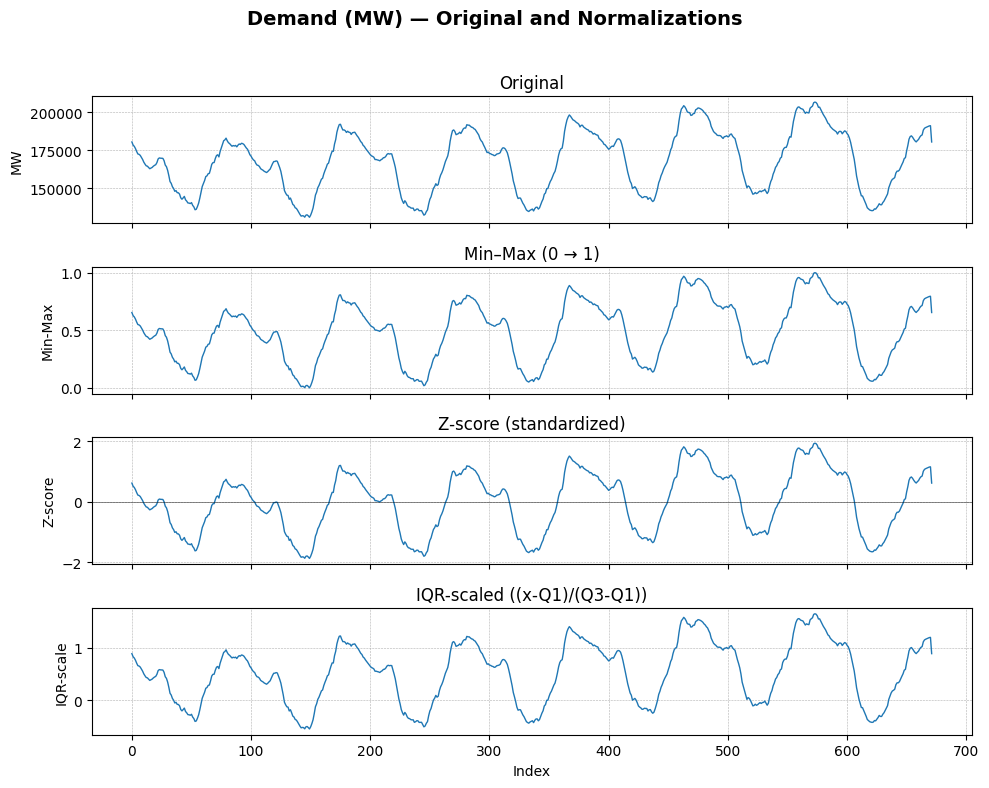

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

FNAME = "data/EE467_EndSem_Data.csv"
COLS = ["Hydro (MW)", "Solar (MW)", "Demand (MW)"]
PRINT_N = 5

df = pd.read_csv(FNAME)               # read CSV; keep as-is (Timestamp column retained if present)
data = df[COLS].copy()                # work on a copy to avoid mutating original df

data = data.apply(pd.to_numeric, errors="coerce")
if data.isnull().any(axis=None):
    data = data.fillna(method="ffill").fillna(method="bfill")
    if data.isnull().any(axis=None):
        # if still NaNs (e.g., all-NaN column) replace with zeros and warn
        print("Warning: some values remain NaN after ffill/bfill; filling with 0.")
        data = data.fillna(0.0)

# NORMALIZATIONS (vectorized, column-wise)

# 1) Min-Max scaling to [0, 1]
min_vals = data.min()
max_vals = data.max()
range_vals = max_vals - min_vals
range_vals = range_vals.replace(0, np.finfo(float).eps)
min_max_norm = data.sub(min_vals).div(range_vals)

# 2) Z-score standardization (centering + scaling by std)
mean_vals = data.mean()
std_vals = data.std(ddof=0).replace(0, np.finfo(float).eps)
z_score_norm = data.sub(mean_vals).div(std_vals)

# 3) IQR (robust) scaling: (x - Q1) / (Q3 - Q1)
Q1 = data.quantile(0.25)
Q3 = data.quantile(0.75)
IQR = (Q3 - Q1).replace(0, np.finfo(float).eps)
iqr_norm = data.sub(Q1).div(IQR)


pd.set_option("display.float_format", lambda x: f"{x:.4f}")

print("\n===== MIN-MAX NORMALIZED (preview) =====")
print(min_max_norm.head(PRINT_N))

print("\n===== Z-SCORE NORMALIZED (preview) =====")
print(z_score_norm.head(PRINT_N))

print("\n===== IQR NORMALIZED (preview) =====")
print(iqr_norm.head(PRINT_N))


pd.reset_option("display.float_format")

# Plotting: per-column compact figures

for col in COLS:
    fig, axes = plt.subplots(4, 1, figsize=(10, 8), sharex=True)
    fig.suptitle(f"{col} — Original and Normalizations", fontsize=14, fontweight="semibold")

    # Top: original series (raw units: MW)
    axes[0].plot(df.index, df[col], linewidth=1)
    axes[0].set_ylabel("MW")
    axes[0].set_title("Original")
    axes[0].grid(True, linestyle="--", linewidth=0.4)

    # Min-Max: scaled to [0,1]
    axes[1].plot(min_max_norm.index, min_max_norm[col], linewidth=1)
    axes[1].set_ylabel("Min-Max")
    axes[1].set_title("Min–Max (0 → 1)")
    axes[1].grid(True, linestyle="--", linewidth=0.4)

    # Z-score: centered & scaled (mean 0, std 1)
    axes[2].plot(z_score_norm.index, z_score_norm[col], linewidth=1)
    axes[2].set_ylabel("Z-score")
    axes[2].set_title("Z-score (standardized)")
    axes[2].axhline(0, color="k", linewidth=0.6, alpha=0.5)  # visual baseline
    axes[2].grid(True, linestyle="--", linewidth=0.4)

    # IQR: robust scaling using quartiles
    axes[3].plot(iqr_norm.index, iqr_norm[col], linewidth=1)
    axes[3].set_ylabel("IQR-scale")
    axes[3].set_title("IQR-scaled ((x-Q1)/(Q3-Q1))")
    axes[3].grid(True, linestyle="--", linewidth=0.4)

    axes[-1].set_xlabel("Index")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()



The three normalization methods rescale Hydro, Solar, and Demand so their patterns become directly comparable despite different magnitudes. Min–Max squeezes each series into 0–1, Z-score shows how far each value deviates from its mean, and IQR scaling highlights variation around the median while reducing the effect of outliers. After normalization, the relative trends and fluctuations across all three energy sources become easier to analyze and suitable for machine-learning or statistical modeling.

Question 2

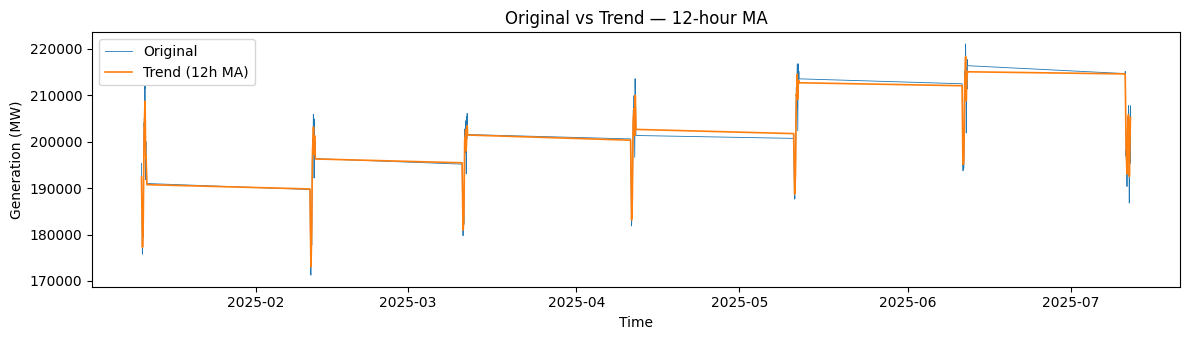

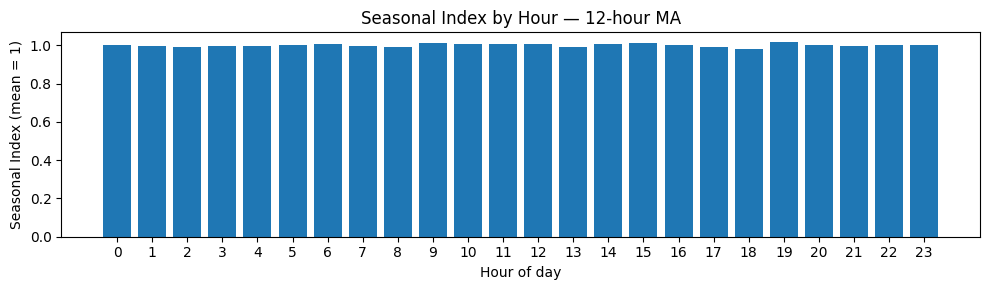

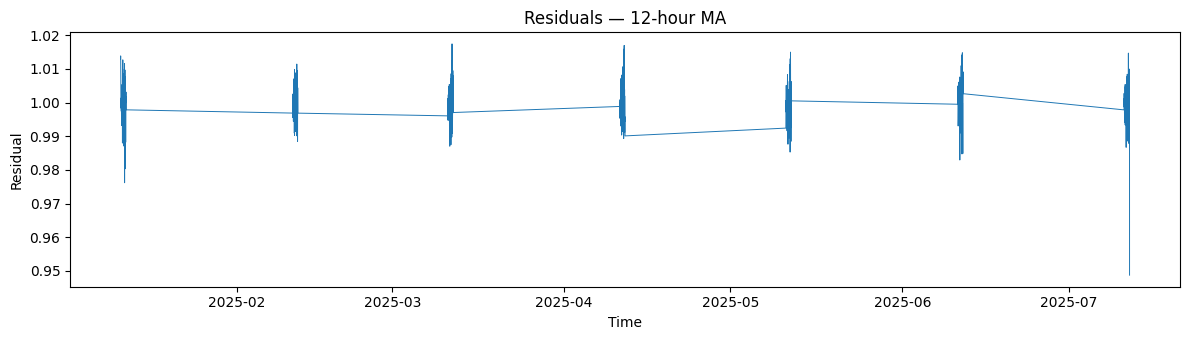

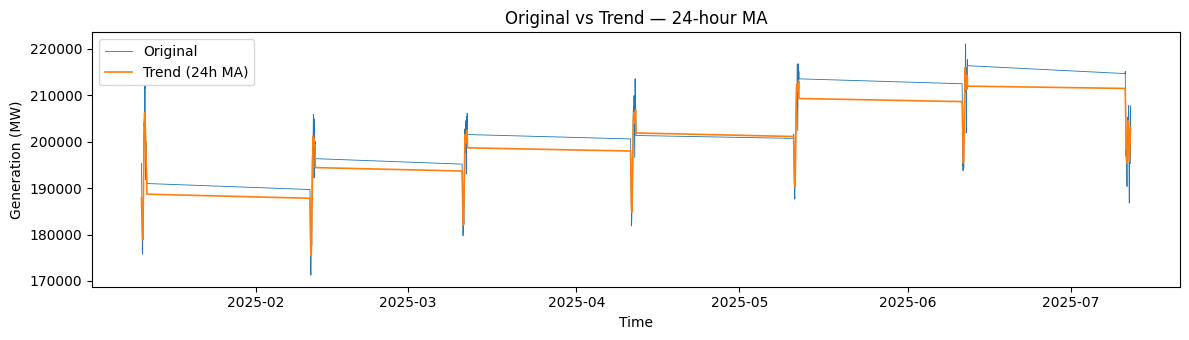

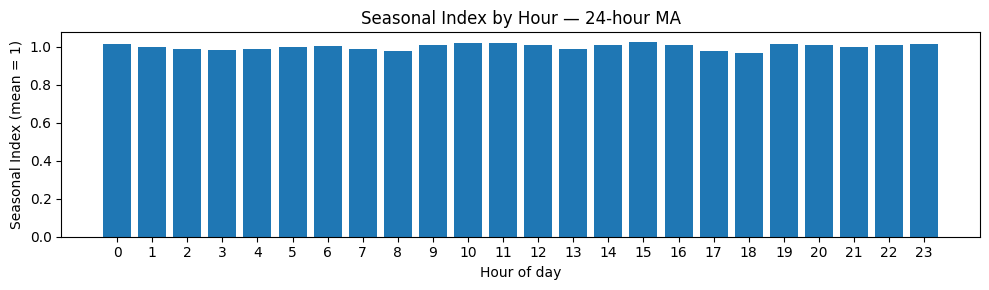

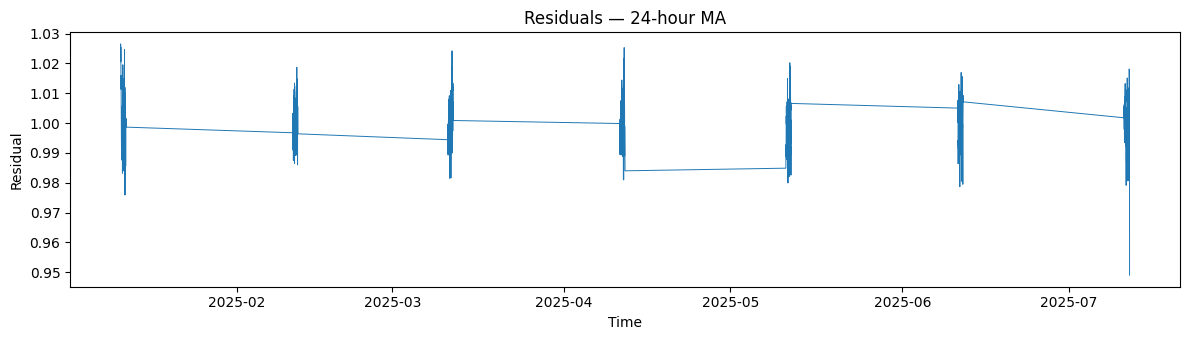

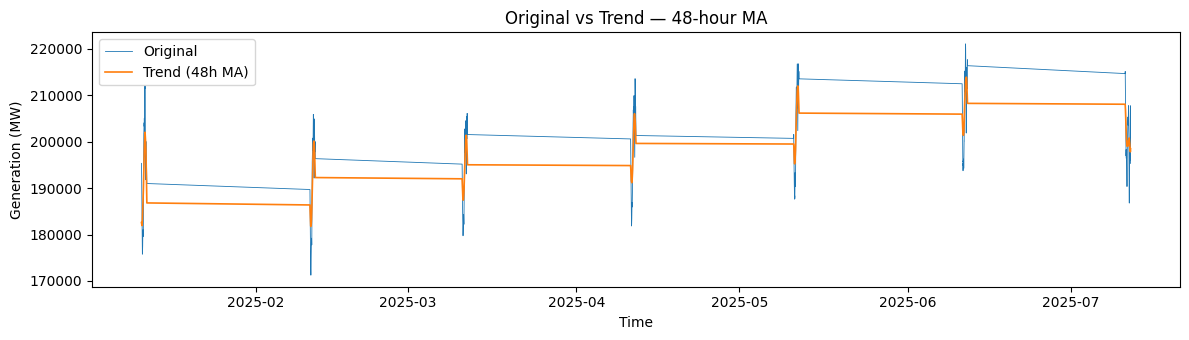

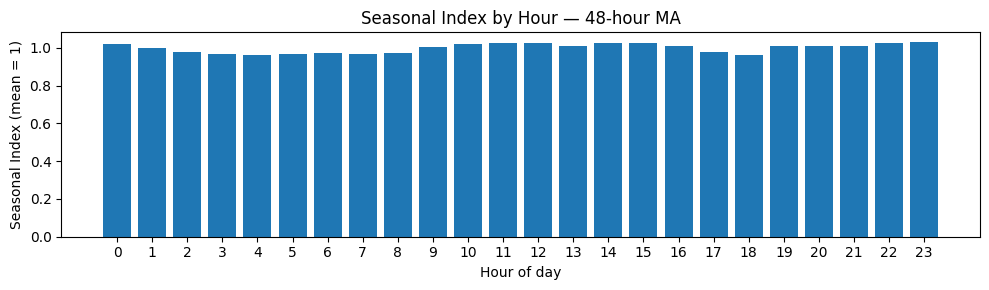

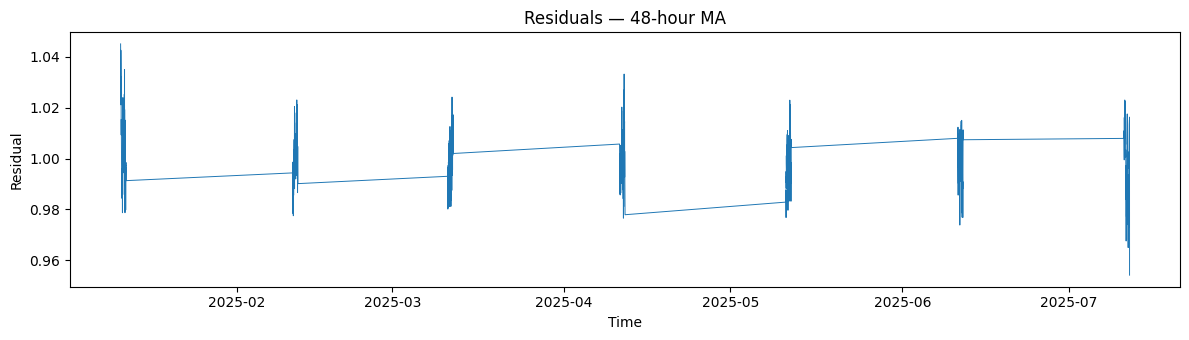


Seasonal Indices (Hours 0–23):
          12        24        48
0   1.002503  1.013327  1.023641
1   0.996854  0.999801  0.999858
2   0.993171  0.986665  0.978876
3   0.993891  0.981323  0.965541
4   0.995094  0.985059  0.960551
5   1.000864  0.997953  0.968024
6   1.003994  1.001746  0.973555
7   0.996230  0.985461  0.967494
8   0.990727  0.979224  0.971941
9   1.009083  1.007285  1.006826
10  1.007871  1.018804  1.023541
11  1.004553  1.016713  1.028593
12  1.005037  1.006322  1.028113
13  0.990469  0.988361  1.011752
14  1.004028  1.007900  1.024037
15  1.009788  1.024037  1.028785
16  1.002654  1.010326  1.009141
17  0.991161  0.977753  0.976739
18  0.981544  0.968526  0.964434
19  1.016525  1.014428  1.008847
20  1.002037  1.009067  1.009200
21  0.994978  0.998826  1.011104
22  1.003473  1.007543  1.028033
23  1.003470  1.013550  1.031373


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("data/EE467_EndSem_Data.csv")

#datetime column to index
datetime_col = [c for c in df.columns if "time" in c.lower() or "date" in c.lower() or "stamp" in c.lower()][0]
df[datetime_col] = pd.to_datetime(df[datetime_col], errors="coerce")
df = df.set_index(datetime_col).sort_index()

# Identifying the Generation column
gen_col = [c for c in df.columns if "generation" in c.lower()][0]
series = df[gen_col].astype(float)

#Windows to analyze (in hours)
windows = [12, 24, 48]

# Storing seasonal indices for reference
seasonal_indices_all = {}

# Main loop for each moving-average window
for w in windows:

    # Trend extraction using centered moving average
    trend = series.rolling(window=w, center=True, min_periods=1).mean()

    # Ratio-to-moving-average (core of multiplicative decomposition) ---
    ratio = series / trend

    # --- Seasonal index estimation by hour-of-day ---
    hour = df.index.hour
    ratio_by_hour = pd.Series(ratio.values, index=hour).groupby(level=0).mean()

    # Filling missing hours (rare) and normalize mean to 1
    full_hours = pd.Index(range(24))
    seasonal = ratio_by_hour.reindex(full_hours)
    seasonal = seasonal.fillna(seasonal.mean())
    seasonal = seasonal / seasonal.mean()

    seasonal_indices_all[w] = seasonal

    # Mapping seasonal index back to full time series
    seasonal_ts = pd.Series([seasonal[h] for h in hour], index=series.index)

    # Residuals = (original / trend) / seasonal
    residuals = ratio / seasonal_ts

    # Plots for this window


    # 1) Original vs Trend
    plt.figure(figsize=(12, 3.5))
    plt.plot(series.index, series, label="Original", linewidth=0.6)
    plt.plot(trend.index, trend, label=f"Trend ({w}h MA)", linewidth=1.2)
    plt.title(f"Original vs Trend — {w}-hour MA")
    plt.xlabel("Time")
    plt.ylabel(gen_col)
    plt.legend()
    plt.tight_layout()
    plt.show()

    # 2) Seasonal Indices (0–23 hours)
    plt.figure(figsize=(10, 3))
    plt.bar(seasonal.index, seasonal.values)
    plt.title(f"Seasonal Index by Hour — {w}-hour MA")
    plt.xlabel("Hour of day")
    plt.ylabel("Seasonal Index (mean = 1)")
    plt.xticks(range(24))
    plt.tight_layout()
    plt.show()

    # 3) Residuals
    plt.figure(figsize=(12, 3.5))
    plt.plot(residuals.index, residuals, linewidth=0.7)
    plt.title(f"Residuals — {w}-hour MA")
    plt.xlabel("Time")
    plt.ylabel("Residual")
    plt.tight_layout()
    plt.show()

#seasonal indices for inspection
seasonal_df = pd.DataFrame(seasonal_indices_all)
print("\nSeasonal Indices (Hours 0–23):")
print(seasonal_df)


The results show that **generation is mainly driven by a smooth long-term trend**, steadily rising from January to July, with minor periodic dips. The **hourly seasonality is weak**, meaning generation doesn’t vary much by hour of the day. The **residuals stay close to 1**, indicating the model captures almost all structure, and only small random fluctuations remain.
